# Getting started with medimg

medimg reconstructs images from incomplete measurements in two settings:
accelerated MRI, where only part of k-space is sampled, and sparse-view CT,
where only a few projection angles are measured. This tutorial covers both,
step by step: the forward models, three reconstruction methods (Tikhonov,
total variation, and wavelet compressed sensing), how to choose their
parameters without knowing the true image, how to use your own images, and
how to check an operator you write yourself.

Run the cells from top to bottom; the whole notebook takes well under a
minute. Install the package first, from the repository root:

```bash
pip install -e ".[dev]"
```

For the mathematics, see `THEORY.md` and `docs/medimg-tech-note.pdf`.

## 1. Setup

Every reconstruction function takes the forward operator `A` and its adjoint
`At` as plain Python functions. That is the whole interface: anything that
maps an image to data, with a matching adjoint, can be plugged in.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import medimg
from medimg.forward import (ct_adjoint, ct_forward, generate_cartesian_mask,
                            mri_adjoint, mri_forward)
from medimg.metrics import psnr, ssim
from medimg.phantoms import shepp_logan
from medimg.reconstruct import cs_fista, tikhonov_cg, tv_chambolle_pock
from medimg.transforms import wavelet_adjoint, wavelet_forward

plt.rcParams.update({"figure.dpi": 110})
print("medimg", medimg.__version__)


def show(images, titles, ref=None, cmap="gray"):
    "Show images side by side; with a reference, add PSNR and SSIM to the titles."
    fig, axes = plt.subplots(1, len(images), figsize=(3.2 * len(images), 3.4))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        if ref is not None and img is not ref:
            title += f"\n{psnr(img, ref):.1f} dB, SSIM {ssim(img, ref):.2f}"
        ax.imshow(img, cmap=cmap)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

medimg 0.2.0


## 2. A test image

`shepp_logan` returns the Shepp-Logan head phantom with values in $[0, 1]$.
It is piecewise constant, which suits total variation; section 8 uses a
natural image as well.

(128, 128) 0.0 0.9999999999999999


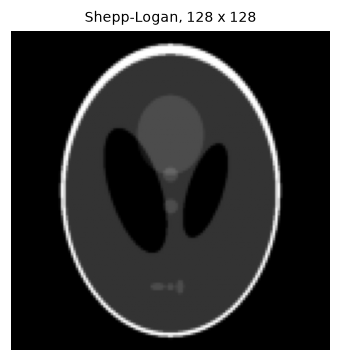

In [2]:
N = 128
x_true = shepp_logan((N, N))
print(x_true.shape, x_true.min(), x_true.max())
show([x_true], ["Shepp-Logan, 128 x 128"])

## 3. MRI: the sampling mask

An MRI scanner measures the Fourier transform of the image (k-space) line by
line. Acquiring fewer lines is faster. `generate_cartesian_mask` keeps a fully
sampled band of central lines, which hold most of the energy, and picks the
remaining lines at random with a density that decreases away from the centre.
The acceleration factor is one over the sampled fraction.

sampled fraction 0.25, acceleration 4.0x


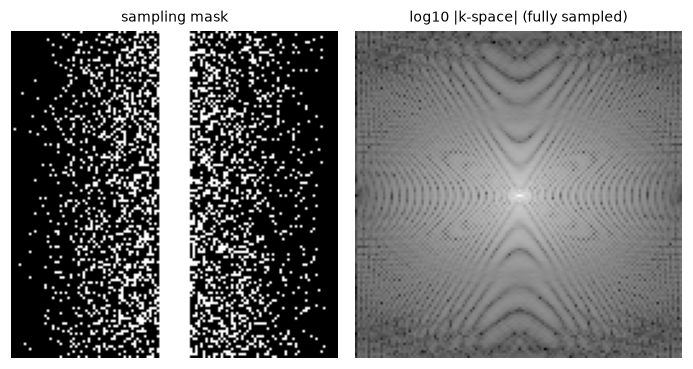

In [3]:
mask = generate_cartesian_mask((N, N), sampling_rate=0.25, calib_lines=12, rng=7)
print(f"sampled fraction {mask.mean():.2f}, acceleration {1 / mask.mean():.1f}x")

kspace_full = mri_forward(x_true, np.ones_like(mask))
show([mask.astype(float), np.log10(np.abs(kspace_full) + 1e-6)],
     ["sampling mask", "log10 |k-space| (fully sampled)"])

## 4. MRI: forward model, noise, and the adjoint

`mri_forward` applies the unitary 2-D FFT, keeps the sampled locations, and
adds complex Gaussian noise there (unsampled locations stay exactly zero).
Because the FFT is unitary, `noise_std` is on the scale of the image
intensities. It is usually easier to think in terms of the signal-to-noise
ratio of the data, so we set `noise_std` from a target SNR.

`mri_adjoint` is the exact adjoint. Applied to the data, it gives the
*zero-filled* reconstruction: the inverse FFT with the missing lines set to
zero, which shows the aliasing caused by undersampling.

noise_std = 9.29e-03 per real and imaginary part


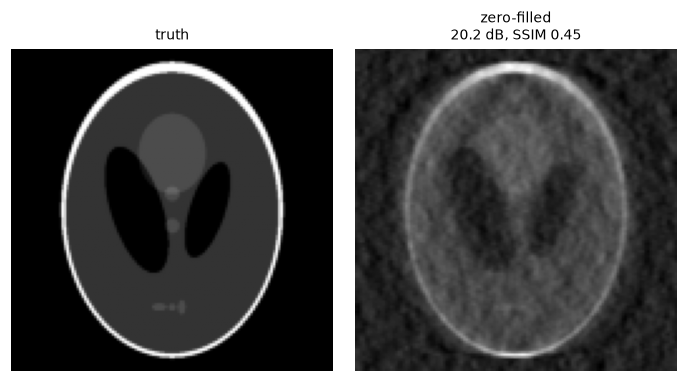

In [4]:
clean = mri_forward(x_true, mask)
SNR_DB = 30.0
signal_rms = np.sqrt(np.mean(np.abs(clean[mask]) ** 2))
noise_std = signal_rms / (np.sqrt(2.0) * 10 ** (SNR_DB / 20))
y = mri_forward(x_true, mask, noise_std=noise_std, rng=8)
print(f"noise_std = {noise_std:.2e} per real and imaginary part")


def A(x):
    return mri_forward(x, mask)


def At(k):
    return mri_adjoint(k, mask)


x_zf = At(y)
show([x_true, x_zf], ["truth", "zero-filled"], ref=x_true)

**Check the adjoint.** Iterative methods assume that `At` is the adjoint of
`A`. The dot-product test checks it: for random $x$ and $y$,
$\langle Ax, y\rangle$ must equal $\langle x, A^*y\rangle$. Do this for any
operator you write; an adjoint that is off by a constant or a transpose makes
the solvers converge to the wrong answer or diverge.

In [5]:
rng = np.random.default_rng(0)
xr = rng.standard_normal((N, N))
yr = (rng.standard_normal((N, N)) + 1j * rng.standard_normal((N, N))) * mask
lhs = np.real(np.vdot(A(xr), yr))
rhs = np.vdot(xr, At(yr))
print(f"<Ax, y> = {lhs:.6f}, <x, A*y> = {rhs:.6f}, ratio = {lhs / rhs:.12f}")

<Ax, y> = -13.594213, <x, A*y> = -13.594213, ratio = 1.000000000000


## 5. MRI: three reconstructions

- **Tikhonov** (`tikhonov_cg`): $\min_x \|Ax-y\|^2 + \lambda\|x\|^2$, solved
  with conjugate gradients. For MRI it barely improves on zero-filling: it
  cannot fill in the missing frequencies.
- **Total variation** (`tv_chambolle_pock`): $\min_x \tfrac12\|Ax-y\|^2 +
  \alpha\,\mathrm{TV}(x)$, solved with the Chambolle-Pock primal-dual method.
  It favours piecewise-constant images.
- **Wavelet compressed sensing** (`cs_fista`): $\min_x \tfrac12\|Ax-y\|^2 +
  \lambda\|Wx\|_1$ with a wavelet transform $W$, solved with FISTA.

The parameters below were found with the sweep in section 6.

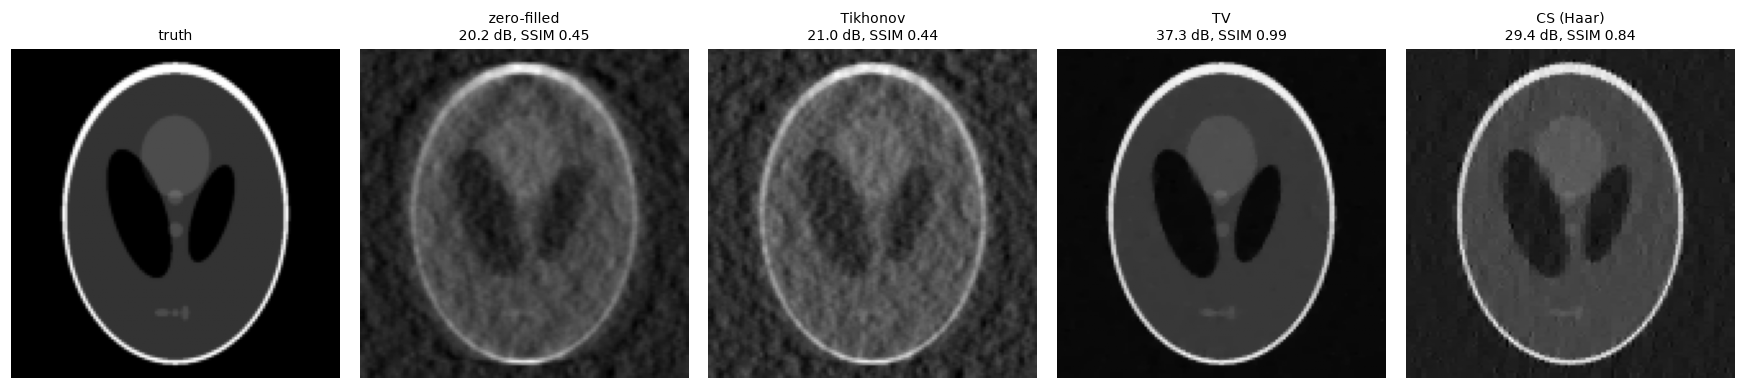

In [6]:
def W(x):
    return wavelet_forward(x, wavelet="haar", level=4)


def Wt(c):
    return wavelet_adjoint(c, wavelet="haar")


x_tik = tikhonov_cg(A, At, y, lambd=1e-3, shape=(N, N), max_iter=200)
x_tv = tv_chambolle_pock(A, At, y, alpha=3e-3, shape=(N, N), max_iter=500, rng=0)
x_cs = cs_fista(A, At, y, W, Wt, lambd=3e-3, shape=(N, N), max_iter=500, rng=0)
show([x_true, x_zf, x_tik, x_tv, x_cs],
     ["truth", "zero-filled", "Tikhonov", "TV", "CS (Haar)"], ref=x_true)

## 6. Choosing the parameter without the true image

The PSNR values above need the true image. With real data you do not have it.
For MRI the forward model is exact, so the misfit between model and data is
pure noise, and the *discrepancy principle* works well: choose the
regularization strength whose residual $\|Ax_\alpha - y\|$ matches the noise
norm, which you can estimate from noise-only scans. Here it is
$\sqrt{2m}\,\sigma$, with $m$ sampled locations and $\sigma$ = `noise_std`.

discrepancy principle: alpha = 5.6e-03 -> 36.2 dB
best (needs the truth): alpha = 3.2e-03 -> 37.5 dB


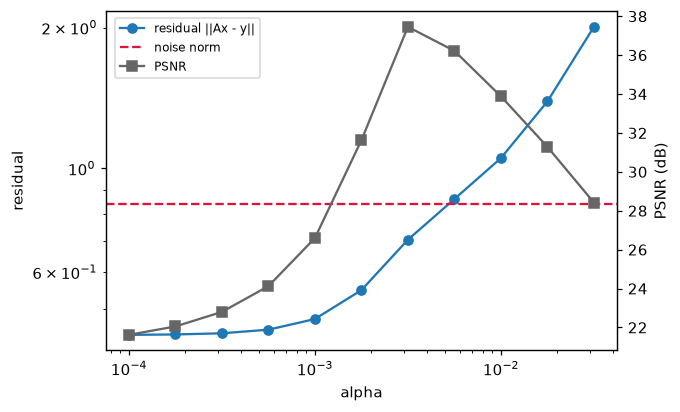

In [7]:
noise_norm = np.sqrt(2 * mask.sum()) * noise_std
alphas = np.logspace(-4, -1.5, 11)
rows = []
for alpha in alphas:
    x = tv_chambolle_pock(A, At, y, alpha=alpha, shape=(N, N), max_iter=500, rng=0)
    rows.append((alpha, np.linalg.norm(A(x) - y), psnr(x, x_true)))
rows = np.array(rows)
pick = rows[np.argmin(np.abs(rows[:, 1] - noise_norm))]
best = rows[np.argmax(rows[:, 2])]
print(f"discrepancy principle: alpha = {pick[0]:.1e} -> {pick[2]:.1f} dB")
print(f"best (needs the truth): alpha = {best[0]:.1e} -> {best[2]:.1f} dB")

fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.loglog(rows[:, 0], rows[:, 1], "o-", label="residual ||Ax - y||")
ax1.axhline(noise_norm, color="crimson", ls="--", label="noise norm")
ax1.set_xlabel("alpha")
ax1.set_ylabel("residual")
ax2 = ax1.twinx()
ax2.semilogx(rows[:, 0], rows[:, 2], "s-", color="0.4", label="PSNR")
ax2.set_ylabel("PSNR (dB)")
fig.legend(loc="upper left", bbox_to_anchor=(0.13, 0.88), fontsize=8)
plt.show()

The discrepancy principle picks $\alpha = 5.6\times10^{-3}$ (36.2 dB), close
to the best value, $3.2\times10^{-3}$ (37.5 dB), which we can only find
because we know the true image. It errs towards slightly more regularization,
which is its usual behaviour. If the noise level is uncertain, plot the
residual against $\alpha$ as above and choose where it crosses your estimate.

## 7. Sparse-view CT

In parallel-beam CT, each projection angle gives one row of the sinogram.
`ct_forward` is a sparse projection matrix whose transpose `ct_adjoint` is the
exact back-projection. With the default `normalize=True` the operator has norm
1, like the MRI operator, so regularization parameters are on comparable
scales. With `normalize=False` it returns line integrals in pixel units, which
is what filtered back-projection (FBP) expects.

The sinogram has one row per angle and one column per detector bin; only
pixels inside the inscribed circle are imaged.

sinogram shape: (30, 128)


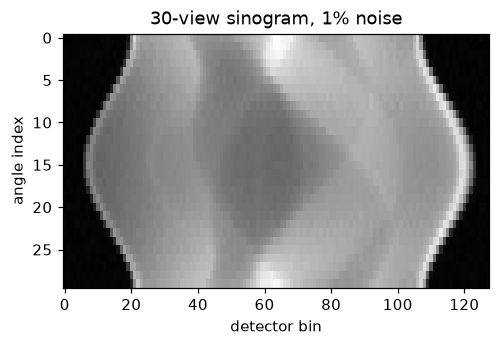

In [8]:
angles = np.linspace(0, np.pi, 30, endpoint=False)
sino_clean = ct_forward(x_true, angles)
rng = np.random.default_rng(9)
NOISE_LEVEL = 0.01
sino = sino_clean + NOISE_LEVEL * np.sqrt(np.mean(sino_clean ** 2)) * rng.standard_normal(sino_clean.shape)
print("sinogram shape:", sino.shape)

fig, ax = plt.subplots(figsize=(5, 3))
ax.imshow(sino, aspect="auto", cmap="gray")
ax.set_xlabel("detector bin")
ax.set_ylabel("angle index")
ax.set_title("30-view sinogram, 1% noise")
plt.show()

FBP is the standard direct method. scikit-image provides it; it needs the
unnormalized sinogram, so we rescale ours.

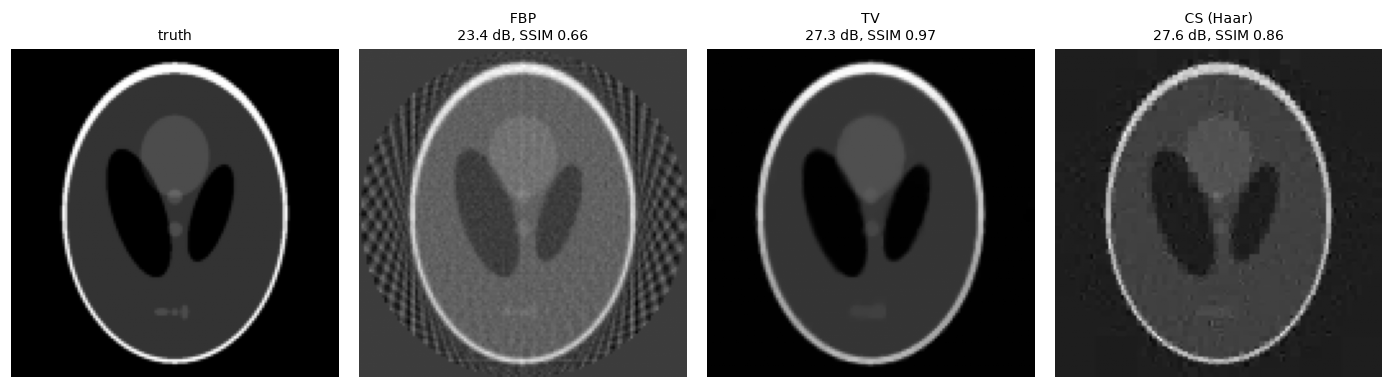

In [9]:
from skimage.transform import iradon


def Act(x):
    return ct_forward(x, angles)


def Actt(s):
    return ct_adjoint(s, angles)


scale = np.linalg.norm(ct_forward(x_true, angles, normalize=False)) / np.linalg.norm(sino_clean)
x_fbp = iradon((sino * scale).T, theta=np.rad2deg(angles), output_size=N,
               circle=True, filter_name="ramp")
x_ct_tv = tv_chambolle_pock(Act, Actt, sino, alpha=1e-3, shape=(N, N), max_iter=500, rng=0)
x_ct_cs = cs_fista(Act, Actt, sino, W, Wt, lambd=3e-4, shape=(N, N), max_iter=500, rng=0)
show([x_true, x_fbp, x_ct_tv, x_ct_cs], ["truth", "FBP", "TV", "CS (Haar)"], ref=x_true)

FBP shows the streaks typical of too few views; TV removes them. The number of
views is the main trade-off in sparse-view CT: fewer views means less dose and
faster scans. To compare fairly, retune $\alpha$ for each number of views,
because the best value depends on how much the data constrain the image:

In [10]:
for n_views in (15, 30, 60, 120):
    ang = np.linspace(0, np.pi, n_views, endpoint=False)
    s0 = ct_forward(x_true, ang)
    s = s0 + NOISE_LEVEL * np.sqrt(np.mean(s0 ** 2)) * np.random.default_rng(1).standard_normal(s0.shape)
    results = []
    for alpha in (1e-4, 3e-4, 1e-3, 3e-3):
        x = tv_chambolle_pock(lambda v: ct_forward(v, ang), lambda w: ct_adjoint(w, ang), s,
                              alpha=alpha, shape=(N, N), max_iter=500, rng=0)
        results.append((psnr(x, x_true), alpha))
    best_psnr, best_alpha = max(results)
    print(f"{n_views:4d} views: best TV {best_psnr:5.1f} dB at alpha = {best_alpha:.0e}")

  15 views: best TV  22.9 dB at alpha = 3e-03


  30 views: best TV  27.3 dB at alpha = 1e-03


  60 views: best TV  30.2 dB at alpha = 1e-04


 120 views: best TV  30.6 dB at alpha = 1e-04


PSNR rises quickly up to about 60 views and then levels off at this noise
level, and the best $\alpha$ falls as the number of views grows.

## 8. Your own images

Any 2-D array with values roughly in $[0, 1]$ works. Square images are needed
for CT. Here is the `camera` test image from scikit-image, which is not
piecewise constant, with the same mask and noise as before.

To load your own file instead, use for example
`img = skimage.io.imread("my_image.png", as_gray=True)`, then resize and
rescale it the same way.

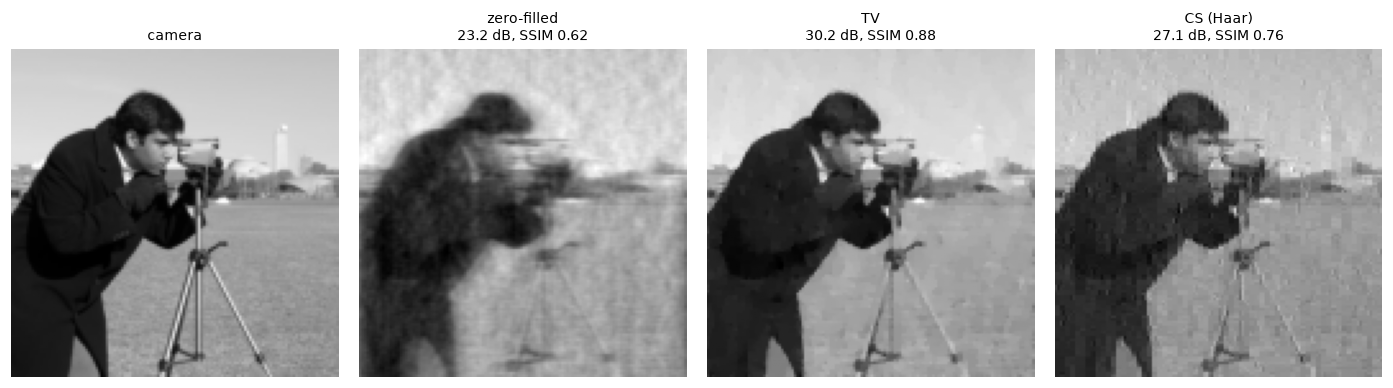

In [11]:
from skimage import data
from skimage.transform import resize

img = resize(data.camera().astype(float) / 255.0, (N, N), anti_aliasing=True)
y_img = mri_forward(img, mask, noise_std=noise_std, rng=3)


rec_tv = tv_chambolle_pock(A, At, y_img, alpha=3e-3, shape=(N, N), max_iter=500, rng=0)
rec_cs = cs_fista(A, At, y_img, W, Wt, lambd=3e-3, shape=(N, N), max_iter=500, rng=0)
show([img, At(y_img), rec_tv, rec_cs], ["camera", "zero-filled", "TV", "CS (Haar)"], ref=img)

TV improves on zero-filling by about 7 dB here, against about 17 dB on the
phantom: natural images are not piecewise constant, so the prior fits less
well. The best wavelet also depends on the image. On this one, Haar (27 dB)
beats the smoother `db4` (about 24 dB); try a few with `wavelet_forward` and
`wavelet_adjoint`, which are orthogonal for any orthogonal wavelet.

## 9. Writing your own operator

To use a different acquisition, write `A` and `At` and run the dot-product
test before reconstructing. As an example, here is a radial-like MRI pattern
built from random lines through the centre of k-space, used with the same MRI
operators:

radial mask samples 32% of k-space
dot-product test ratio: 1.000000000000


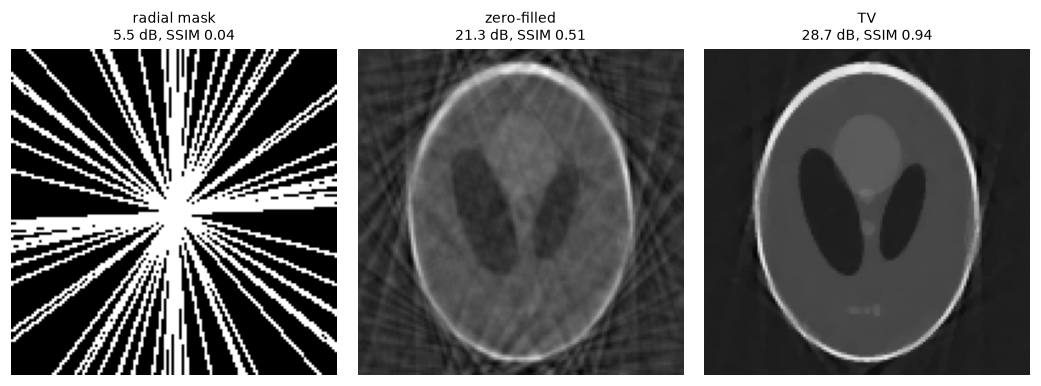

In [12]:
yy, xx = np.mgrid[:N, :N] - N // 2
theta = np.arctan2(yy, xx) % np.pi
radial = np.zeros((N, N), dtype=bool)
for t in np.random.default_rng(4).uniform(0, np.pi, 40):
    radial |= np.abs(np.sin(theta - t)) * np.hypot(xx, yy) < 0.7
print(f"radial mask samples {radial.mean():.0%} of k-space")


def Ar(x):
    return mri_forward(x, radial)


def Art(k):
    return mri_adjoint(k, radial)


lhs = np.real(np.vdot(Ar(xr), yr * radial))
rhs = np.vdot(xr, Art(yr * radial))
print(f"dot-product test ratio: {lhs / rhs:.12f}")

y_rad = mri_forward(x_true, radial, noise_std=noise_std, rng=5)
x_rad = tv_chambolle_pock(Ar, Art, y_rad, alpha=3e-3, shape=(N, N), max_iter=500, rng=0)
show([radial.astype(float), Art(y_rad), x_rad], ["radial mask", "zero-filled", "TV"], ref=x_true)

The solvers estimate the Lipschitz constant $\|A\|^2$ by power iteration when
you do not pass `L`, so operators that are not normalized also work; you then
have to rescale the regularization parameters.

## Where to go next

- `THEORY.md` and `docs/medimg-tech-note.pdf`: the models, the algorithms,
  and the verification results.
- `examples/01_mri_cs.py` and `examples/02_ct_sparse_view.py`: the full
  256 x 256 experiments behind the figures in `figures/`.